# 01 · Multi-Armed Bandits: the exploration vs exploitation trade-off

Notebook 00 assumed we **know** the environment and can plan. Real agents must *learn from trial and
error*, and that raises a question supervised learning never asks: **should I take the action that looks
best so far, or try something else to learn more?**

To study that question in isolation we remove everything else from RL: no states, no delayed rewards,
just one decision repeated many times. This is the **multi-armed bandit**. It is not a toy for LLMs: a
single prompt answered by one sampled response and scored by a verifier *is* a (contextual) bandit, and
most LLM RL algorithms treat the whole response as one "arm pull".

By the end you will have implemented, from scratch in pure Python (and one in PyTorch):

1. **greedy** and **ε-greedy** with incremental mean updates, plus **optimistic initialisation**;
2. **UCB1** (optimism under uncertainty, derived from Hoeffding's inequality);
3. **Thompson sampling** (Bayesian posterior sampling with Beta distributions);
4. the **gradient bandit** (softmax policy + baseline), the direct ancestor of REINFORCE, PPO and GRPO;
5. a **contextual bandit** trained with policy gradients in PyTorch: a miniature of "RLHF as a bandit".

```mermaid
flowchart LR
    N00[00 Foundations] --> N01["<b>01 Bandits</b><br/>exploration<br/>(you are here)"]:::here
    N01 --> N02[02 Tabular TD / Q-learning]
    N02 --> N03[03 DQN]
    N02 --> N04[04 Policy gradient]
    N04 --> N05[05 Actor-critic, GAE]
    N05 --> N06[06 TRPO / PPO]
    N06 --> N07[07 RLHF]
    N07 --> N08[08 DPO family]
    N07 --> N09[09 GRPO family]
    N09 --> N10[10 Reasoning RLVR]
    N08 --> N11[11 RLAIF / self-play]
    N09 --> N12[12 RL for VLMs]
    N10 --> N13[13 Frontier & pitfalls]
    classDef here fill:#2563eb,color:#fff,stroke:#1e3a8a
```

## 1. The problem

**Analogy: a new city, ten restaurants.** Every evening you pick one restaurant. Each has an unknown
probability $p_a$ of giving you a great meal. If you always return to the best one you've found so far,
you might never discover that the place around the corner is better. If you keep trying new places, you
waste evenings on bad meals. Bandit algorithms are principled answers to "how much should I explore?".

Formally a $K$-armed bandit has actions $a \in \{1,\dots,K\}$, each with an unknown reward distribution with
mean $q_*(a) = \mathbb{E}[r \mid a]$. At each step $t = 1..T$ the agent picks $a_t$ and receives
$r_t \sim$ distribution of arm $a_t$. We use **Bernoulli** arms ($r \in \{0, 1\}$, like "answer correct /
incorrect" for an LLM), so $q_*(a) = p_a$.

**How do we score an algorithm?** By **regret**: how much reward we lost compared to always pulling the
best arm $a^* = \arg\max_a q_*(a)$:

$$\text{Regret}(T) = \sum_{t=1}^{T} \big(q_*(a^*) - q_*(a_t)\big).$$

* Always exploring at random gives **linear** regret: we lose a constant amount every step.
* Never exploring (greedy) can also give linear regret: if we lock onto a bad arm we lose forever.
* Lai & Robbins (1985) proved that any good algorithm must have regret growing at least like
  $\log T$, and UCB and Thompson sampling achieve this logarithmic rate.

```mermaid
flowchart LR
    S["estimate of each arm<br/>(mean, uncertainty)"] --> D{"decide"}
    D -- "exploit:<br/>best estimate" --> R["pull arm,<br/>observe reward"]
    D -- "explore:<br/>uncertain arm" --> R
    R --> U["update estimate<br/>of that arm"]
    U --> S
```

In [1]:
# Setup: make the shared `rlkit` helpers (plots, GIFs, toy envs, tiny models) importable.
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))
%matplotlib inline

In [2]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import torch

from rlkit.viz import COLORS, Animator, save_figure, setup_style, smooth

setup_style()
random.seed(0)
torch.manual_seed(0)


class BernoulliBandit:
    """K arms; pulling arm a returns 1 with probability probs[a], else 0."""

    def __init__(self, probs, rng):
        self.probs = list(probs)
        self.rng = rng
        self.best = max(self.probs)
        self.best_arm = self.probs.index(self.best)

    def pull(self, a):
        return 1.0 if self.rng.random() < self.probs[a] else 0.0


def argmax_random_tie(values, rng):
    """argmax that breaks ties at random (plain max() always prefers arm 0, a subtle bias)."""
    best = max(values)
    return rng.choice([i for i, v in enumerate(values) if v == best])


bandit = BernoulliBandit([0.3, 0.5, 0.55, 0.7], random.Random(0))
print("true arm probabilities:", bandit.probs, "-> best arm", bandit.best_arm)
print("10 pulls of arm 3:", [bandit.pull(3) for _ in range(10)])

true arm probabilities: [0.3, 0.5, 0.55, 0.7] -> best arm 3
10 pulls of arm 3: [0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 0.0, 1.0, 1.0, 1.0]


## 2. Estimating an arm's value: the incremental mean

Every algorithm below keeps an estimate $Q(a)$ of $q_*(a)$. The natural estimate is the sample average of
the rewards seen from that arm. Storing all rewards is wasteful; the average can be updated in $O(1)$:

$$Q_{n+1} = \frac{1}{n}\sum_{i=1}^{n} r_i = \frac{1}{n}\Big(r_n + (n-1) Q_n\Big) = Q_n + \frac{1}{n}\big(r_n - Q_n\big).$$

Read the last form as **new estimate = old estimate + step size × (target − old estimate)**. This pattern
(an *error-correcting update*) appears everywhere in RL: TD learning, Q-learning, value-function regression in
PPO. With a constant step size $\alpha$ instead of $1/n$ we get an exponential moving average that forgets old
data, which is useful when the arm's distribution changes over time (non-stationary, like a policy that is
itself being trained).

In [3]:
Q, n = 0.0, 0
rewards = [1, 0, 1, 1, 0, 1]
for r in rewards:
    n += 1
    Q += (r - Q) / n          # incremental mean
print(f"incremental mean = {Q:.4f}, batch mean = {sum(rewards) / len(rewards):.4f}")
assert abs(Q - sum(rewards) / len(rewards)) < 1e-12

incremental mean = 0.6667, batch mean = 0.6667


## 3. Algorithm 1: greedy and ε-greedy

**Idea:** usually exploit the best estimate, but with a small probability $\varepsilon$ pick an arm uniformly at
random so every arm keeps being sampled.

> **Algorithm steps: ε-greedy**
> 1. **Initialise** $Q(a) = Q_0$ and counts $N(a) = 0$ for every arm.
> 2. **Choose:** with probability $\varepsilon$ pick a random arm (*explore*); otherwise pick $\arg\max_a Q(a)$, breaking ties randomly (*exploit*).
> 3. **Act:** pull the arm, observe $r$.
> 4. **Update** only the pulled arm: $N(a) \mathrel{+}= 1$, $Q(a) \mathrel{+}= \alpha_n (r - Q(a))$ with $\alpha_n = 1/N(a)$ (sample mean) or a constant $\alpha$.
> 5. Repeat from step 2.
>
> * $\varepsilon = 0$ is **pure greedy**: it can lock onto a bad arm forever after one unlucky reward from the good arm.
> * **Optimistic initialisation** ($Q_0 = 1$, larger than any real reward, constant $\alpha$) is a trick that makes even greedy explore: every untried arm looks great until it is tried and "disappoints".
> * Weakness: exploration is *undirected*: ε-greedy wastes pulls on arms it already knows are bad, forever, so its regret grows linearly with slope $\approx \varepsilon \cdot$ (average gap).

In [4]:
class EpsilonGreedy:
    """epsilon-greedy with sample-average (step_size=None) or constant step-size updates."""

    def __init__(self, k, epsilon=0.1, init=0.0, step_size=None, rng=None):
        self.Q = [init] * k
        self.N = [0] * k
        self.epsilon, self.step_size = epsilon, step_size
        self.rng = rng or random.Random()

    def select(self, t):
        if self.rng.random() < self.epsilon:
            return self.rng.randrange(len(self.Q))         # explore
        return argmax_random_tie(self.Q, self.rng)         # exploit

    def update(self, a, r):
        self.N[a] += 1
        alpha = self.step_size if self.step_size is not None else 1.0 / self.N[a]
        self.Q[a] += alpha * (r - self.Q[a])

## 4. Algorithm 2: UCB1, optimism in the face of uncertainty

**Idea:** instead of exploring at random, explore the arms we are *unsure* about. Give each arm a bonus that
is large when it has been tried rarely, then act greedily on *estimate + bonus*: "assume each arm is as good
as it plausibly could be".

**Deriving the bonus.** For rewards in $[0, 1]$, **Hoeffding's inequality** bounds how far a sample mean of
$n$ pulls can be from the truth:

$$P\big(q_*(a) > Q(a) + u\big) \le e^{-2 n u^2}.$$

Choose the failure probability to shrink over time, $e^{-2nu^2} = t^{-4}$, and solve for $u$:

$$u = \sqrt{\frac{2 \ln t}{n}} \quad\Longrightarrow\quad a_t = \arg\max_a \left[Q(a) + c\sqrt{\frac{\ln t}{N(a)}}\right], \; c = \sqrt{2}.$$

So $Q(a) + \sqrt{2 \ln t / N(a)}$ is an **upper confidence bound** that is wrong with tiny probability. This is
UCB1 (Auer, Cesa-Bianchi & Fischer, 2002), with regret $O(\sum_{a: \Delta_a > 0} \frac{\ln T}{\Delta_a})$, where $\Delta_a = q_*(a^*) - q_*(a)$.

> **Algorithm steps: UCB1**
> 1. **Pull every arm once** (the bonus is infinite for $N(a) = 0$).
> 2. **Score** each arm with $U(a) = Q(a) + c\sqrt{\ln t / N(a)}$.
>    *The $\ln t$ term grows slowly, so a neglected arm's bonus keeps rising until it is tried again; the $1/N(a)$ term shrinks the bonus of well-known arms.*
> 3. **Pull** $\arg\max_a U(a)$, observe $r$.
> 4. **Update** $N(a)$ and the sample mean $Q(a)$.
> 5. Repeat. Bad arms get pulled only $O(\ln T / \Delta_a^2)$ times: exploration *fades* automatically.

In [5]:
class UCB1:
    """UCB1 (Auer et al. 2002): greedy on Q(a) + c * sqrt(ln t / N(a))."""

    def __init__(self, k, c=math.sqrt(2), rng=None):
        self.Q = [0.0] * k
        self.N = [0] * k
        self.c = c
        self.rng = rng or random.Random()

    def bounds(self, t):
        return [q + self.c * math.sqrt(math.log(t) / n) for q, n in zip(self.Q, self.N)]

    def select(self, t):
        for a, n in enumerate(self.N):
            if n == 0:
                return a                                  # try every arm once
        return argmax_random_tie(self.bounds(t), self.rng)

    def update(self, a, r):
        self.N[a] += 1
        self.Q[a] += (r - self.Q[a]) / self.N[a]

The animation shows UCB1 on the 4-arm bandit from above. Bars are the estimates $Q(a)$, the whiskers reach up
to the upper confidence bound $U(a)$, the dashed markers are the true $p_a$ (hidden from the agent), and the
highlighted arm is the one pulled at that step. Watch the whiskers of rarely pulled arms *grow* (the $\ln t$
term) until they become the highest and get pulled, while the bars converge to the true values.


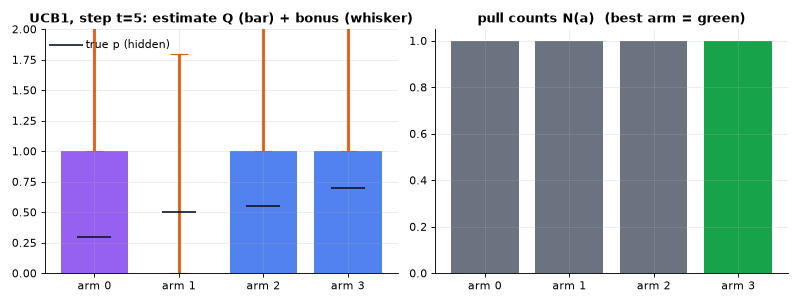

PosixPath('/Users/naveenkumarbasaanitha/Music/HaloDiffusionLLM/assets/rl/course/01_ucb.gif')

In [6]:
def record_ucb(probs, T, seed):
    rng = random.Random(seed)
    env, agent = BernoulliBandit(probs, rng), UCB1(len(probs), rng=random.Random(seed + 1))
    frames = []
    for t in range(1, T + 1):
        a = agent.select(t)
        ub = agent.bounds(t) if min(agent.N) > 0 else [float("nan")] * len(probs)
        frames.append((t, a, list(agent.Q), list(agent.N), ub))
        agent.update(a, env.pull(a))
    return frames


PROBS4 = [0.3, 0.5, 0.55, 0.7]
ucb_frames = record_ucb(PROBS4, T=2000, seed=3)
ucb_show = sorted(set(np.geomspace(5, 2000, 50).astype(int)))


def draw_ucb(fig, i):
    fig.clf()
    t, a, Q, N, ub = ucb_frames[ucb_show[min(i, len(ucb_show) - 1)] - 1]
    ax1, ax2 = fig.add_subplot(1, 2, 1), fig.add_subplot(1, 2, 2)
    x = np.arange(len(PROBS4))
    colors = [COLORS["accent"] if j == a else COLORS["policy"] for j in x]
    ax1.bar(x, Q, color=colors, alpha=0.8)
    ax1.errorbar(x, Q, yerr=[np.zeros(len(x)), np.array(ub) - np.array(Q)], fmt="none",
                 ecolor=COLORS["value"], capsize=8, lw=2.5)
    ax1.scatter(x, PROBS4, marker="_", s=900, color=COLORS["ink"], zorder=5, label="true p (hidden)")
    ax1.set_ylim(0, 2.0); ax1.set_xticks(x, [f"arm {j}" for j in x])
    ax1.set_title(f"UCB1, step t={t}: estimate Q (bar) + bonus (whisker)"); ax1.legend(loc="upper left")
    ax2.bar(x, N, color=[COLORS["reward"] if j == 3 else COLORS["reference"] for j in x])
    ax2.set_xticks(x, [f"arm {j}" for j in x]); ax2.set_title("pull counts N(a)  (best arm = green)")
    fig.tight_layout()


Animator(draw_ucb, n_frames=len(ucb_show) + 5, figsize=(10, 3.8), fps=5).save("01_ucb.gif")

## 5. Algorithm 3: Thompson sampling, probability matching with a posterior

**Idea (Thompson, 1933):** keep a full *belief distribution* over each arm's success probability. Each step,
**sample** one plausible value from every arm's belief and pull the arm whose sample is highest. An arm is
pulled with exactly the probability that it is the best arm under your current beliefs ("probability
matching"). Uncertain arms produce wide, occasionally high samples, so they get explored; well-known bad
arms almost never produce a winning sample.

**The Bayesian bookkeeping.** For a Bernoulli arm the conjugate prior is the **Beta** distribution:

$$p(\theta) = \mathrm{Beta}(\theta; \alpha, \beta) \propto \theta^{\alpha-1}(1-\theta)^{\beta-1}.$$

After observing reward $r \in \{0,1\}$ the posterior is again a Beta (multiply prior by likelihood $\theta^r (1-\theta)^{1-r}$):

$$\mathrm{Beta}(\alpha, \beta) \times \theta^r(1-\theta)^{1-r} \propto \theta^{\alpha + r - 1}(1-\theta)^{\beta + (1-r) - 1} \;\Rightarrow\; \alpha \leftarrow \alpha + r,\;\; \beta \leftarrow \beta + 1 - r.$$

So the whole posterior is two counters per arm: $\alpha - 1$ = successes, $\beta - 1$ = failures. Its mean is
$\alpha/(\alpha+\beta)$ and its width shrinks like $1/\sqrt{\alpha + \beta}$.

> **Algorithm steps: Thompson sampling (Beta-Bernoulli)**
> 1. **Prior:** $\alpha_a = \beta_a = 1$ for every arm (Beta(1,1) = uniform on [0,1]: "no idea").
> 2. **Sample** $\tilde\theta_a \sim \mathrm{Beta}(\alpha_a, \beta_a)$ independently for each arm.
> 3. **Act greedily on the samples:** pull $a_t = \arg\max_a \tilde\theta_a$.
> 4. **Bayesian update** of the pulled arm only: $\alpha_a \mathrel{+}= r$, $\beta_a \mathrel{+}= 1 - r$.
> 5. Repeat. There is no $\varepsilon$ or $c$ to tune: the posterior width *is* the exploration schedule.

In [7]:
class ThompsonBeta:
    """Thompson sampling for Bernoulli arms with Beta(1, 1) priors."""

    def __init__(self, k, rng=None):
        self.alpha = [1.0] * k
        self.beta = [1.0] * k
        self.rng = rng or random.Random()

    def select(self, t):
        samples = [self.rng.betavariate(a, b) for a, b in zip(self.alpha, self.beta)]
        return max(range(len(samples)), key=samples.__getitem__)

    def update(self, a, r):
        self.alpha[a] += r
        self.beta[a] += 1 - r

    @property
    def Q(self):
        return [a / (a + b) for a, b in zip(self.alpha, self.beta)]


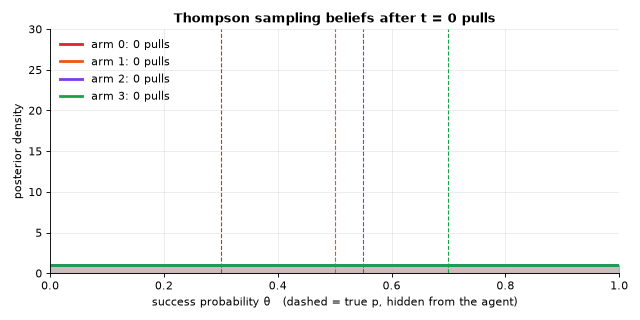

Thompson pulls per arm after 1000 steps: [11, 26, 131, 832]


In [8]:
def beta_pdf(x, a, b):
    """Beta density via log-gamma (pure Python maths, vectorised over x with numpy for plotting)."""
    log_norm = math.lgamma(a + b) - math.lgamma(a) - math.lgamma(b)
    x = np.clip(x, 1e-6, 1 - 1e-6)
    return np.exp(log_norm + (a - 1) * np.log(x) + (b - 1) * np.log(1 - x))


def record_thompson(probs, T, seed):
    rng = random.Random(seed)
    env, agent = BernoulliBandit(probs, rng), ThompsonBeta(len(probs), rng=random.Random(seed + 1))
    history = [(list(agent.alpha), list(agent.beta))]
    for t in range(1, T + 1):
        a = agent.select(t)
        agent.update(a, env.pull(a))
        history.append((list(agent.alpha), list(agent.beta)))
    return history


ts_hist = record_thompson(PROBS4, T=1000, seed=5)
ts_show = [0] + sorted(set(np.geomspace(1, 1000, 45).astype(int)))
xs = np.linspace(0, 1, 300)
arm_colors = [COLORS["penalty"], COLORS["value"], COLORS["accent"], COLORS["reward"]]


def draw_thompson(fig, i):
    fig.clf()
    t = ts_show[min(i, len(ts_show) - 1)]
    alpha, beta = ts_hist[t]
    ax = fig.add_subplot(1, 1, 1)
    for j, (a, b) in enumerate(zip(alpha, beta)):
        pulls = int(a + b - 2)
        ax.plot(xs, beta_pdf(xs, a, b), color=arm_colors[j], lw=2.5, label=f"arm {j}: {pulls} pulls")
        ax.fill_between(xs, beta_pdf(xs, a, b), color=arm_colors[j], alpha=0.12)
        ax.axvline(PROBS4[j], color=arm_colors[j], ls="--", lw=1)
    ax.set_ylim(0, 30); ax.set_xlim(0, 1)
    ax.set_xlabel("success probability θ   (dashed = true p, hidden from the agent)")
    ax.set_ylabel("posterior density")
    ax.set_title(f"Thompson sampling beliefs after t = {t} pulls")
    ax.legend(loc="upper left")
    fig.tight_layout()


Animator(draw_thompson, n_frames=len(ts_show) + 6, figsize=(8, 4), fps=5).save("01_thompson.gif")
final_pulls = [int(a + b - 2) for a, b in zip(*ts_hist[-1])]
print("Thompson pulls per arm after 1000 steps:", final_pulls)
assert final_pulls[3] == max(final_pulls), "the best arm should receive the most pulls"

In the GIF the posteriors start flat (Beta(1,1)), the best arm's curve becomes a tall, narrow spike near its
true value (it gets most pulls), while the clearly bad arm (red) stays wide: Thompson sampling stops pulling
it as soon as it is *confidently worse*, without needing to know its value precisely. That is efficient
exploration.

## 6. Algorithm 4: the gradient bandit, the first policy-gradient method

All methods so far learn **values** and derive actions from them. The gradient bandit learns a **policy**
directly: a softmax over learnable preferences $H(a)$,

$$\pi(a) = \frac{e^{H(a)}}{\sum_b e^{H(b)}},$$

and does **gradient ascent on the expected reward** $J(H) = \mathbb{E}_{a \sim \pi}[r] = \sum_a \pi(a)\, q_*(a)$.
This section is the most important one for the rest of the course, because REINFORCE, PPO and GRPO are this
exact idea with the softmax over arms replaced by an LLM's softmax over tokens.

**Derivation.** We cannot compute $\nabla J$ directly because $q_*$ is unknown, but we can turn it into an
expectation we can *sample*:

$$
\begin{aligned}
\nabla_H J &= \sum_a q_*(a)\, \nabla_H \pi(a)
            = \sum_a q_*(a)\, \pi(a)\, \nabla_H \log \pi(a) \qquad \text{(log-derivative trick: } \nabla\pi = \pi\nabla\log\pi) \\
           &= \mathbb{E}_{a \sim \pi}\big[\, q_*(a)\, \nabla_H \log \pi(a) \,\big]
            = \mathbb{E}_{a \sim \pi,\, r}\big[\, r\, \nabla_H \log \pi(a) \,\big].
\end{aligned}
$$

So "sample an action, observe its reward $r$, step along $r \nabla \log \pi(a)$" is an **unbiased** estimate of the
gradient. For a softmax, $\frac{\partial \log \pi(A)}{\partial H(b)} = \mathbb{1}[b = A] - \pi(b)$.

**The baseline.** Since $\sum_a \nabla \pi(a) = \nabla 1 = 0$, we can subtract any constant $\bar r$ from $r$
without changing the expected gradient: $\mathbb{E}[(r - \bar r)\nabla\log\pi(a)] = \nabla J$. But it changes
the **variance** a lot: with 0/1 rewards and no baseline every successful pull pushes its arm up and failures
do nothing; with a baseline equal to the average reward, better-than-average outcomes push up and
worse-than-average outcomes push *down*. $r - \bar r$ is our first **advantage**. (GRPO's "group mean" baseline in
notebook 09 is exactly this, computed over a group of sampled responses.)

> **Algorithm steps: gradient bandit** (Sutton & Barto §2.8; Williams 1992)
> 1. **Initialise** preferences $H(a) = 0$ (uniform policy) and the baseline $\bar r = 0$.
> 2. **Sample** an action from the policy: $A_t \sim \pi = \mathrm{softmax}(H)$. *(Exploration comes from the policy's own randomness.)*
> 3. **Observe** reward $r_t$ and compute the advantage $r_t - \bar r_t$.
> 4. **Policy-gradient step** for every arm $b$: $H(b) \mathrel{+}= \alpha\,(r_t - \bar r_t)\,(\mathbb{1}[b = A_t] - \pi(b))$.
>    *The chosen arm moves in the direction of the advantage; all other arms move the opposite way in proportion to their probability.*
> 5. **Update the baseline**: $\bar r \mathrel{+}= (r_t - \bar r)/t$ (running mean of rewards).
> 6. Repeat. As the policy concentrates on the best arm, exploration decreases naturally.

In [9]:
class GradientBandit:
    """Softmax policy over preferences H, trained by stochastic gradient ascent on E[r] (pure Python)."""

    def __init__(self, k, alpha=0.1, use_baseline=True, rng=None):
        self.H = [0.0] * k
        self.alpha, self.use_baseline = alpha, use_baseline
        self.baseline, self.t = 0.0, 0
        self.rng = rng or random.Random()

    @property
    def pi(self):
        m = max(self.H)                                   # subtract max for numerical stability
        e = [math.exp(h - m) for h in self.H]
        z = sum(e)
        return [x / z for x in e]

    def select(self, t):
        return self.rng.choices(range(len(self.H)), weights=self.pi)[0]

    def update(self, a, r):
        self.t += 1
        advantage = r - (self.baseline if self.use_baseline else 0.0)
        pi = self.pi
        for b in range(len(self.H)):
            self.H[b] += self.alpha * advantage * ((1.0 if b == a else 0.0) - pi[b])
        self.baseline += (r - self.baseline) / self.t

**The same update with PyTorch autograd.** Writing the loss as $-\,(r - \bar r)\log\pi_\theta(A)$ and calling
`.backward()` gives exactly the hand-derived update. This "surrogate loss" trick is how every policy-gradient
method for LLMs is implemented: you never write $\mathbb{1}[b=A] - \pi(b)$ by hand; autograd does it through
the whole transformer.

In [10]:
gb = GradientBandit(4, alpha=0.1, rng=random.Random(0))
gb.H = [0.2, -0.1, 0.4, 0.0]
gb.baseline, gb.t = 0.5, 10
H_torch = torch.tensor(gb.H, requires_grad=True)

a, r = 2, 1.0                                  # pretend we pulled arm 2 and got reward 1
baseline_before = gb.baseline
gb.update(a, r)                                # pure-Python update

logp = torch.log_softmax(H_torch, dim=0)[a]
loss = -(r - baseline_before) * logp           # policy-gradient surrogate loss
loss.backward()
with torch.no_grad():
    H_new = H_torch - 0.1 * H_torch.grad       # one SGD step with lr = alpha
print("pure python :", [round(h, 6) for h in gb.H])
print("torch SGD   :", [round(h, 6) for h in H_new.tolist()])
assert torch.allclose(H_new, torch.tensor(gb.H), atol=1e-6)

pure python : [0.186776, -0.109797, 0.433848, -0.010827]
torch SGD   : [0.186776, -0.109797, 0.433848, -0.010827]


The animation compares the gradient bandit **with** and **without** a baseline. We use a bandit where *every*
arm pays out often ($p = 0.80, 0.85, 0.88, 0.92$), which is the typical LLM situation: most sampled answers get a
decent reward-model score, and the differences between them are small. Bars are $\pi(a)$ **averaged over 60
independent runs** (single runs are too noisy to compare); the green bar is the best arm.

Without the baseline almost every pull returns $r = 1$, so *whatever arm was sampled gets pushed up*: the
update mostly reinforces the policy's own random choices ("rich get richer") and only weakly distinguishes
good from slightly-worse arms. With the baseline, $r - \bar r$ is negative whenever an arm fails, so worse arms
are actively pushed down. (On the earlier bandit with $p$ from 0.3 to 0.7 the two variants perform about the
same: the baseline matters most when rewards are large relative to their differences.)

mean π(best arm) after 1500 steps: with baseline 0.798, without 0.605



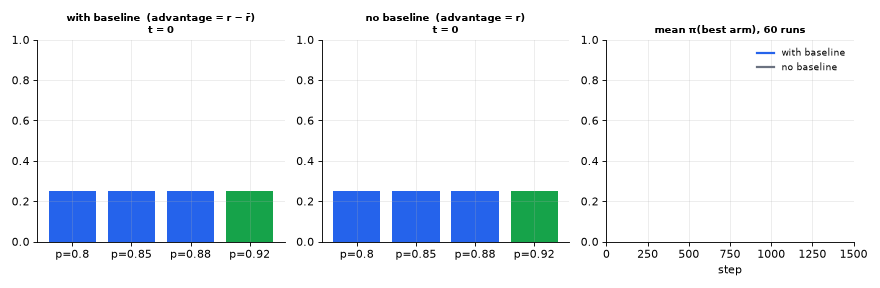

PosixPath('/Users/naveenkumarbasaanitha/Music/HaloDiffusionLLM/assets/rl/course/01_gradient_bandit.gif')

In [11]:
def record_gradient(probs, T, seed, use_baseline, alpha=0.1):
    rng = random.Random(seed)
    env, agent = BernoulliBandit(probs, rng), GradientBandit(len(probs), alpha, use_baseline, random.Random(seed + 1))
    hist = [agent.pi]
    for t in range(1, T + 1):
        a = agent.select(t)
        agent.update(a, env.pull(a))
        hist.append(agent.pi)
    return hist


GB_T, GB_RUNS = 1500, 60
PROBS_HIGH = [0.80, 0.85, 0.88, 0.92]


def averaged_policies(use_baseline):
    """pi_t averaged over GB_RUNS seeds -> array (GB_T + 1, 4)."""
    return np.mean([record_gradient(PROBS_HIGH, GB_T, seed=s, use_baseline=use_baseline) for s in range(GB_RUNS)], axis=0)


gb_with, gb_without = averaged_policies(True), averaged_policies(False)
gb_show = list(np.linspace(0, GB_T, 50).astype(int))
print(f"mean π(best arm) after {GB_T} steps: with baseline {gb_with[-1][3]:.3f}, without {gb_without[-1][3]:.3f}")
assert gb_with[-1][3] > gb_without[-1][3] + 0.1


def draw_gradient(fig, i):
    fig.clf()
    t = gb_show[min(i, len(gb_show) - 1)]
    for j, (name, hist) in enumerate([("with baseline  (advantage = r − r̄)", gb_with),
                                      ("no baseline  (advantage = r)", gb_without)]):
        ax = fig.add_subplot(1, 3, j + 1)
        ax.bar(range(4), hist[t], color=[COLORS["reward"] if k == 3 else COLORS["policy"] for k in range(4)])
        ax.set_ylim(0, 1); ax.set_xticks(range(4), [f"p={p}" for p in PROBS_HIGH])
        ax.set_title(f"{name}\nt = {t}", fontsize=9)
    ax = fig.add_subplot(1, 3, 3)
    ax.plot([h[3] for h in gb_with[: t + 1]], color=COLORS["policy"], lw=2, label="with baseline")
    ax.plot([h[3] for h in gb_without[: t + 1]], color=COLORS["reference"], lw=2, label="no baseline")
    ax.set_xlim(0, GB_T); ax.set_ylim(0, 1); ax.set_title(f"mean π(best arm), {GB_RUNS} runs", fontsize=9)
    ax.set_xlabel("step"); ax.legend(fontsize=8)
    fig.tight_layout()


Animator(draw_gradient, n_frames=len(gb_show) + 5, figsize=(11, 3.6), fps=6).save("01_gradient_bandit.gif")

## 7. The showdown: regret on a 10-armed testbed

Now a fair comparison: 200 independent bandit problems, each with 10 Bernoulli arms whose probabilities are
drawn uniformly from $[0, 1]$, run for 2000 steps. We average the per-step regret and the fraction of times
each algorithm pulls the optimal arm (the experimental protocol of Sutton & Barto's 10-armed testbed, with
Bernoulli rewards).

```mermaid
flowchart TD
    Q["How does the algorithm explore?"] --> U["Undirected<br/>(random noise)"]
    Q --> D["Directed by uncertainty"]
    Q --> P["Through a stochastic policy"]
    U --> EG["ε-greedy<br/>regret ~ linear"]
    U --> OI["optimistic init<br/>(explores early only)"]
    D --> UCB["UCB1: optimism<br/>regret ~ log T"]
    D --> TS["Thompson: posterior sampling<br/>regret ~ log T"]
    P --> GB["gradient bandit<br/>(→ REINFORCE, PPO, GRPO)"]
```

In [12]:
def run_testbed(make_agent, n_runs=200, T=2000, k=10, seed=0):
    """Average per-step regret and optimal-action rate over n_runs random Bernoulli bandits."""
    regret = [0.0] * T
    optimal = [0.0] * T
    for run in range(n_runs):
        rng = random.Random(seed * 100_000 + run)
        env = BernoulliBandit([rng.random() for _ in range(k)], rng)
        agent = make_agent(k, random.Random(run + 7))
        for t in range(1, T + 1):
            a = agent.select(t)
            agent.update(a, env.pull(a))
            regret[t - 1] += (env.best - env.probs[a]) / n_runs
            optimal[t - 1] += (a == env.best_arm) / n_runs
    return regret, optimal


ALGOS = {
    "random":            lambda k, rng: EpsilonGreedy(k, epsilon=1.0, rng=rng),
    "greedy":            lambda k, rng: EpsilonGreedy(k, epsilon=0.0, rng=rng),
    "ε-greedy (0.1)":    lambda k, rng: EpsilonGreedy(k, epsilon=0.1, rng=rng),
    "optimistic greedy": lambda k, rng: EpsilonGreedy(k, epsilon=0.0, init=1.0, step_size=0.1, rng=rng),
    "UCB1":              lambda k, rng: UCB1(k, rng=rng),
    "UCB (c=0.5)":       lambda k, rng: UCB1(k, c=0.5, rng=rng),
    "Thompson":          lambda k, rng: ThompsonBeta(k, rng=rng),
    "gradient bandit":   lambda k, rng: GradientBandit(k, alpha=0.2, rng=rng),
}
results = {name: run_testbed(make) for name, make in ALGOS.items()}
cum_regret = {name: float(np.sum(reg)) for name, (reg, _) in results.items()}
for name, total in sorted(cum_regret.items(), key=lambda kv: kv[1]):
    print(f"{name:<18} cumulative regret after 2000 steps = {total:7.1f}   "
          f"optimal-arm rate (last 200 steps) = {np.mean(results[name][1][-200:]):.2f}")

Thompson           cumulative regret after 2000 steps =    32.6   optimal-arm rate (last 200 steps) = 0.94
UCB (c=0.5)        cumulative regret after 2000 steps =    44.7   optimal-arm rate (last 200 steps) = 0.84
optimistic greedy  cumulative regret after 2000 steps =    51.4   optimal-arm rate (last 200 steps) = 0.82
gradient bandit    cumulative regret after 2000 steps =    93.4   optimal-arm rate (last 200 steps) = 0.80
ε-greedy (0.1)     cumulative regret after 2000 steps =   112.0   optimal-arm rate (last 200 steps) = 0.77
UCB1               cumulative regret after 2000 steps =   185.1   optimal-arm rate (last 200 steps) = 0.61
greedy             cumulative regret after 2000 steps =   550.4   optimal-arm rate (last 200 steps) = 0.12
random             cumulative regret after 2000 steps =   800.1   optimal-arm rate (last 200 steps) = 0.10


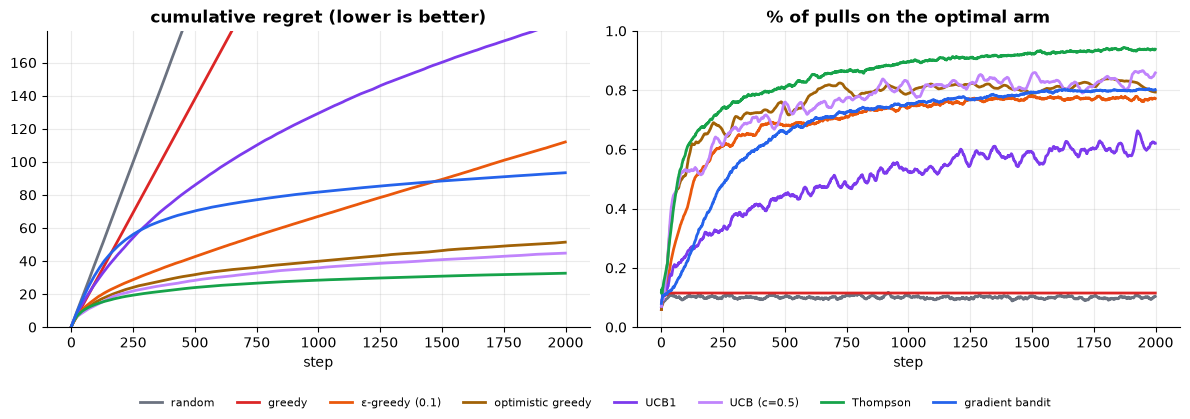

In [13]:
palette = {"random": COLORS["reference"], "greedy": COLORS["penalty"], "ε-greedy (0.1)": COLORS["value"],
           "optimistic greedy": "#a16207", "UCB1": COLORS["accent"], "UCB (c=0.5)": "#c084fc", "Thompson": COLORS["reward"],
           "gradient bandit": COLORS["policy"]}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for name, (reg, opt) in results.items():
    axes[0].plot(np.cumsum(reg), label=name, color=palette[name], lw=2)
    axes[1].plot(smooth(opt, 25), label=name, color=palette[name], lw=2)
axes[0].set_title("cumulative regret (lower is better)"); axes[0].set_xlabel("step")
axes[0].set_ylim(0, cum_regret["ε-greedy (0.1)"] * 1.6)
axes[1].set_title("% of pulls on the optimal arm"); axes[1].set_xlabel("step"); axes[1].set_ylim(0, 1)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=8, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1))
save_figure(fig, "01_regret_comparison.png")
plt.show()

assert cum_regret["Thompson"] < cum_regret["ε-greedy (0.1)"] < cum_regret["random"]
assert cum_regret["UCB1"] < cum_regret["random"] / 3
assert all(cum_regret[n] < cum_regret["random"] for n in ALGOS if n != "random")
assert cum_regret["UCB (c=0.5)"] < cum_regret["ε-greedy (0.1)"]

ε-greedy (0.1)  cumulative regret  894.0   per-step regret: first 2k steps 0.0629, last 2k steps 0.0422
UCB1            cumulative regret  441.5   per-step regret: first 2k steps 0.0921, last 2k steps 0.0074


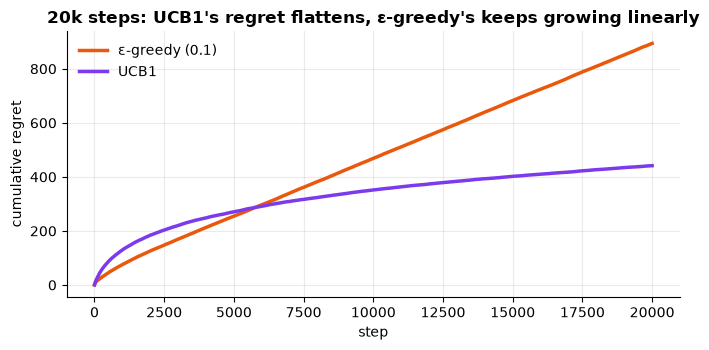

In [14]:
# Long horizon: 20,000 steps, 50 runs. Per-step regret should keep falling for UCB1 but stay flat for ε-greedy.
long_runs = {name: run_testbed(ALGOS[name], n_runs=50, T=20_000, seed=1)[0] for name in ["ε-greedy (0.1)", "UCB1"]}
fig, ax = plt.subplots(figsize=(7, 3.6))
for name, reg in long_runs.items():
    ax.plot(np.cumsum(reg), color=palette[name], lw=2.5, label=name)
    early, late = np.mean(reg[:2000]), np.mean(reg[-2000:])
    print(f"{name:<15} cumulative regret {np.sum(reg):6.1f}   per-step regret: first 2k steps {early:.4f}, last 2k steps {late:.4f}")
ax.set_title("20k steps: UCB1's regret flattens, ε-greedy's keeps growing linearly")
ax.set_xlabel("step"); ax.set_ylabel("cumulative regret"); ax.legend()
plt.tight_layout(); plt.show()
assert np.mean(long_runs["UCB1"][-2000:]) < 0.5 * np.mean(long_runs["ε-greedy (0.1)"][-2000:])
assert np.sum(long_runs["UCB1"]) < np.sum(long_runs["ε-greedy (0.1)"])

How to read the plot:

* **random** has a straight, steep regret line: linear regret, it never uses what it learned.
* **greedy** learns quickly but its regret keeps growing: in some runs it locks onto a suboptimal arm forever.
* **ε-greedy** fixes the lock-in but its regret grows linearly with slope ≈ ε × (average gap), because it never stops exploring.
* **Thompson** is the clear winner here, and its regret curve bends over (logarithmic growth).
* **UCB1 with the textbook $c=\sqrt{2}$ looks worse than ε-greedy at 2000 steps!** The Hoeffding bonus is a
  *worst-case* bound, so it is very conservative: with 10 arms it keeps re-checking bad arms for a long time.
  Its advantage is *asymptotic*: the bonus keeps shrinking, ε-greedy's exploration does not. A smaller,
  tuned bonus (**UCB c=0.5**) is far better at this horizon, at the price of losing the formal guarantee.
* The **gradient bandit** learns a policy directly; its performance depends on the step size α (try 0.05 or 0.5).

Look at the *shapes* of the curves rather than the exact numbers: they depend on the seed and the number of runs.
The next cell checks the "asymptotic" claim by running UCB1 and ε-greedy ten times longer.

## 8. A contextual bandit in PyTorch: "RLHF is a bandit"

In a **contextual bandit** the agent first observes a context $x$ (a prompt!) and then picks an action
(a response!). The best action depends on the context. There is still no sequence of states: one decision,
one reward. That is exactly how sequence-level LLM RL is framed: the *prompt* is the context, the *whole
response* is the action, and the reward model or verifier gives one scalar.

```mermaid
flowchart LR
    X["context x<br/>(prompt)"] --> PI["policy π_θ(y|x)<br/>(softmax / LLM)"]
    PI -- "sample y" --> RW["reward r(x, y)<br/>(verifier / reward model)"]
    RW -- "advantage r − b(x)" --> UP["policy-gradient step<br/>∇ log π_θ(y|x) · (r − b)"]
    UP --> PI
```

Below: 4 "prompt types" and 6 "candidate responses". Each (prompt, response) pair has a hidden success
probability. A linear softmax policy is trained with the batched gradient-bandit update (REINFORCE with a
per-prompt mean baseline), written with autograd. Replace the linear layer with a transformer and the 6
candidate responses with all possible token sequences and you have the core of LLM policy-gradient RL.

expected reward: uniform policy 0.387 -> trained 0.896  (best possible 0.900)


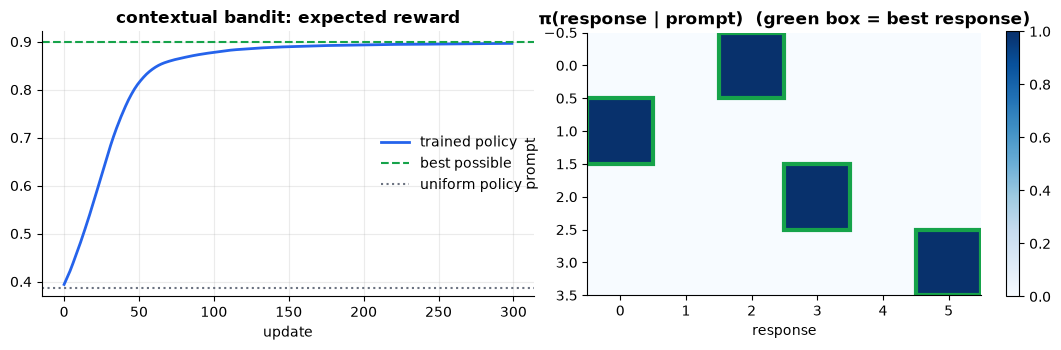

In [15]:
n_ctx, n_actions = 4, 6
g = torch.Generator().manual_seed(0)
true_p = torch.rand(n_ctx, n_actions, generator=g) * 0.6       # mediocre responses...
true_p[torch.arange(n_ctx), torch.randperm(n_actions, generator=g)[:n_ctx]] = 0.9   # ...one great one per prompt

policy = torch.nn.Linear(n_ctx, n_actions, bias=False)          # logits = W · onehot(x)
torch.nn.init.zeros_(policy.weight)                             # start uniform
opt = torch.optim.Adam(policy.parameters(), lr=0.05)


def expected_reward(policy):
    with torch.no_grad():
        probs = torch.softmax(policy(torch.eye(n_ctx)), dim=-1)
        return (probs * true_p).sum(-1).mean().item()


history = []
for step in range(300):
    ctx = torch.randint(0, n_ctx, (64,))                              # a batch of prompts
    logits = policy(torch.nn.functional.one_hot(ctx, n_ctx).float())
    dist = torch.distributions.Categorical(logits=logits)
    actions = dist.sample()                                           # "generate" a response per prompt
    rewards = torch.bernoulli(true_p[ctx, actions])                   # verifier says 0 or 1
    # per-prompt baseline = mean reward of that prompt type in the batch (a group baseline, as in GRPO)
    baseline = torch.zeros(n_ctx).index_add(0, ctx, rewards) / torch.bincount(ctx, minlength=n_ctx).clamp(min=1)
    advantage = rewards - baseline[ctx]
    loss = -(advantage * dist.log_prob(actions)).mean()               # policy-gradient surrogate
    opt.zero_grad(); loss.backward(); opt.step()
    history.append(expected_reward(policy))

best_possible = true_p.max(-1).values.mean().item()
uniform_value = true_p.mean().item()
print(f"expected reward: uniform policy {uniform_value:.3f} -> trained {history[-1]:.3f}  (best possible {best_possible:.3f})")
assert history[-1] > 0.9 * best_possible

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(history, color=COLORS["policy"], lw=2, label="trained policy")
axes[0].axhline(best_possible, color=COLORS["reward"], ls="--", label="best possible")
axes[0].axhline(uniform_value, color=COLORS["reference"], ls=":", label="uniform policy")
axes[0].set_title("contextual bandit: expected reward"); axes[0].set_xlabel("update"); axes[0].legend()
im = axes[1].imshow(torch.softmax(policy(torch.eye(n_ctx)), -1).detach(), cmap="Blues", vmin=0, vmax=1)
for c in range(n_ctx):
    axes[1].add_patch(plt.Rectangle((true_p[c].argmax() - 0.5, c - 0.5), 1, 1, fill=False, ec=COLORS["reward"], lw=3))
axes[1].set_title("π(response | prompt)  (green box = best response)")
axes[1].set_xlabel("response"); axes[1].set_ylabel("prompt"); axes[1].grid(False)
plt.colorbar(im, ax=axes[1])
plt.tight_layout()
save_figure(fig, "01_contextual_bandit.png")
plt.show()

## 9. Exploration in LLMs: temperature, best-of-N and pass@k

LLMs explore by **sampling**: the temperature $\tau$ in $\pi(y) \propto \exp(\text{logit}(y)/\tau)$ plays the role of
$\varepsilon$. Low temperature ≈ greedy (exploit), high temperature ≈ more exploration. A second, very common
"bandit" trick for LLMs is **best-of-N**: sample $N$ responses and keep the best according to a verifier or
reward model. If one sample is correct with probability $p$, the chance that at least one of $N$ is correct is

$$\text{pass@}N = 1 - (1 - p)^N.$$

This is why RL on LLMs needs a policy that already succeeds *sometimes*: if $p \approx 0$, no amount of sampling
finds a reward signal (the exploration problem), and if $p \approx 1$ every sample gets the same reward and the
advantage $r - \bar r$ is zero (nothing to learn). Notebooks 09-10 return to this "zero-variance group" problem.

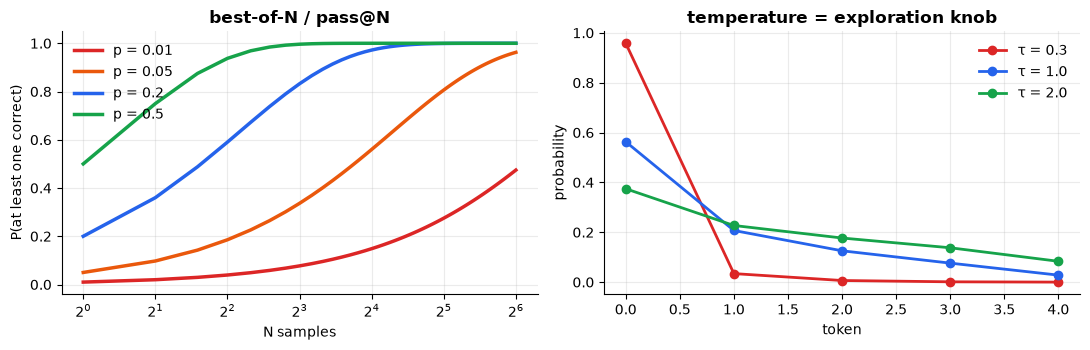

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
N = np.arange(1, 65)
for p, color in [(0.01, COLORS["penalty"]), (0.05, COLORS["value"]), (0.2, COLORS["policy"]), (0.5, COLORS["reward"])]:
    axes[0].plot(N, 1 - (1 - p) ** N, lw=2.5, color=color, label=f"p = {p}")
axes[0].set_xscale("log", base=2); axes[0].set_xlabel("N samples"); axes[0].set_ylabel("P(at least one correct)")
axes[0].set_title("best-of-N / pass@N"); axes[0].legend()

logits = torch.tensor([2.0, 1.0, 0.5, 0.0, -1.0])
for tau, color in [(0.3, COLORS["penalty"]), (1.0, COLORS["policy"]), (2.0, COLORS["reward"])]:
    axes[1].plot(torch.softmax(logits / tau, 0), "o-", color=color, lw=2, label=f"τ = {tau}")
axes[1].set_title("temperature = exploration knob"); axes[1].set_xlabel("token"); axes[1].set_ylabel("probability")
axes[1].legend()
plt.tight_layout()
save_figure(fig, "01_llm_exploration.png")
plt.show()

## 10. Common pitfalls

* **Deterministic tie-breaking.** `max(range(k), key=Q.__getitem__)` always picks the lowest index among ties: with all-zero initial estimates greedy then *never* tries most arms. Break ties randomly.
* **Using a constant step size with stationary arms** keeps the estimate noisy forever; using $1/n$ with *non-stationary* arms (e.g. a reward model that drifts) reacts too slowly.
* **Optimistic initialisation only helps at the start**: once the optimism is "used up" it explores no more, so it fails if the problem changes.
* **Forgetting the baseline in policy gradients**: still unbiased, but when all rewards are high (every answer gets a decent score) the update mostly reinforces whatever was sampled and learning is much slower (see the gradient-bandit GIF).
* **Comparing algorithms on one seed**: bandit curves are very noisy; always average over many runs.
* **Mis-scaled UCB bonus**: $\sqrt{2\ln t / N}$ assumes rewards in $[0, 1]$; with rewards in $[0, 100]$ you must scale $c$ accordingly. And a guarantee is not the same as good finite-horizon performance: the textbook constant over-explores (section 7).

## 11. How this connects to LLM/VLM training

* **Sequence-level LLM RL is a contextual bandit**: prompt = context, response = action, reward model / verifier = reward. RLOO, GRPO and DPO (notebooks 08-09) all treat the response as one action.
* The **gradient bandit with a baseline** is the core update of REINFORCE (04), PPO (06), RLOO and GRPO (09); GRPO's baseline is the mean reward of a *group* of responses to the same prompt, like our per-prompt baseline in section 8.
* **Temperature** is the LLM's exploration knob; RL can *collapse* it (entropy collapse, notebook 13), turning the policy greedy and stopping exploration.
* **Best-of-N** is the inference-time cousin of RL and is the basis of rejection-sampling fine-tuning (notebook 10).
* **Thompson-style uncertainty** shows up in active preference collection and ensembles of reward models for exploration.
* For **VLMs** nothing changes: the context now includes the image.

## 12. Cheat sheet

| Algorithm | Action selection | Update | Exploration | Regret |
|---|---|---|---|---|
| greedy | $\arg\max_a Q(a)$ | $Q \mathrel{+}= \frac{1}{N}(r - Q)$ | none (can lock in) | linear (worst case) |
| ε-greedy | random w.p. ε, else greedy | same | undirected, never stops | linear (slope ∝ ε) |
| optimistic init | greedy, $Q_0$ high | constant α | early only | depends |
| UCB1 | $\arg\max_a Q(a) + \sqrt{2\ln t / N(a)}$ | sample mean | directed by uncertainty | $O(\log T)$ (conservative early) |
| Thompson | $\arg\max_a \tilde\theta_a,\ \tilde\theta_a \sim \text{Beta}(\alpha_a,\beta_a)$ | $\alpha \mathrel{+}= r,\ \beta \mathrel{+}= 1-r$ | posterior sampling | $O(\log T)$ |
| gradient bandit | $a \sim \text{softmax}(H)$ | $H \mathrel{+}= \alpha(r - \bar r)(\mathbb{1}[b=a] - \pi_b)$ | stochastic policy | depends on α |
| contextual PG | $y \sim \pi_\theta(\cdot \mid x)$ | $\nabla_\theta\, (r - b(x)) \log\pi_\theta(y \mid x)$ | sampling / temperature | n/a |

**Next:** notebook 02 brings back the *states* and learns values from experience without a model: Monte
Carlo, TD learning, SARSA and Q-learning.